# Week 10: Charts, maps, and word clouds

**Charts and maps**

First we are going to load up the data vis libraries we need for this exercise. pydeck renders maps as HTML files, so we also are adding a library that allows us to display HTML in the notebook

In [1]:
import json                                  # to read the GeoJSON shape files
import re                                    # regular expressions, from Part 9, to pick out the words

import matplotlib.pyplot as plt              # to display the word clouds
import pandas as pd                          # tables of data
import plotly.express as px                  # the quick way to make interactive charts and maps ("px")
import pydeck as pdk                         # 3D maps
from IPython.display import HTML, IFrame     # to show web pages and HTML inside the notebook
from wordcloud import STOPWORDS, WordCloud   # STOPWORDS is a set of common words to leave out


## House and senate polling data (last week)

The polling data, which comes from the [New York Times](https://www.nytimes.com/interactive/polls/latest-polls.html), has already been cleaned and averaged in a separate notebook, `week10_polling_prep.ipynb`, which saved the latest week of polling for each district and each state in two small CSV files. Let's look at two different methods for displaying this data: organizing it into a bar chart, and plotting it on a map.

In [2]:
# read the two CSV files made by the prep notebook into tables (DataFrames)
house = pd.read_csv("house_average_recent.csv")
senate = pd.read_csv("senate_average_recent.csv")

# len() of a table is its number of rows: one row per district, and one row per state
print(len(house), "House districts,", len(senate), "Senate states")

# .head() shows the first five rows, so we can see what the columns look like
house.head()

114 House districts, 29 Senate states


,id,state,district,dem,rep,margin,polls,latest,days_old
0,AK-1,AK,1,5.8,45.8,-40.1,1,2026-10-30,1
1,AL-2,AL,2,45.0,49.5,-4.5,1,2026-10-25,6
2,AR-2,AR,2,48.0,52.0,-4.0,1,2026-10-14,17
3,AZ-1,AZ,1,49.4,45.0,4.4,1,2026-10-28,3
4,AZ-2,AZ,2,50.0,48.0,2.0,1,2026-10-14,17


Each row has the average Democratic and Republican numbers (`dem`, `rep`), the **margin** (`dem` minus `rep`, so positive means a Democratic lead), the number of `polls` averaged, and the date of the `latest` poll.

In [3]:
# the Senate table has the same columns, except there's no district number
senate.head()

,state,dem,rep,margin,polls,latest,days_old
0,AK,48.7,47.1,1.6,2,2026-10-30,2
1,AL,39.5,47.8,-8.3,1,2026-10-24,8
2,AR,39.0,55.0,-16.0,1,2026-10-28,4
3,FL,43.6,49.3,-5.7,7,2026-10-30,2
4,GA,53.9,43.8,10.1,3,2026-10-23,9


## Bar charts: splitting each race into Democrat, Republican, and other

A bar chart makes it easy to compare *how much* each race is leading by. Let's draw one horizontal bar for each race, split into the Democratic share, the Republican share, and everything else.

Our files only have `dem` and `rep`. The rest of each poll is third-party candidates and undecided voters, so we can work it out with some simple math in pandas: **other = 100 - dem - rep**.

We use `clip()` to clean negative values that might emerge as artefacts of the averaging process: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.clip.html

In [4]:
# make a new column: whatever is left of the 100 percent after the Democratic and Republican numbers.
# .clip(lower=0) turns any tiny negative result (from averaging) into 0, and .round(1) keeps one decimal place
senate["other"] = (100 - senate["dem"] - senate["rep"]).clip(lower=0).round(1)
house["other"] = (100 - house["dem"] - house["rep"]).clip(lower=0).round(1)

senate[["state", "dem", "rep", "other"]].head()

,state,dem,rep,other
0,AK,48.7,47.1,4.2
1,AL,39.5,47.8,12.7
2,AR,39.0,55.0,6.0
3,FL,43.6,49.3,7.1
4,GA,53.9,43.8,2.3


### Senate: one bar per state

`px.bar()` takes a **list of columns** for `x`, and stacks them. First we `rename()` the columns to the names we want in the legend. `orientation="h"` makes the bars horizontal (so the states go on `y`). We put `other` in the middle, so the Democratic share starts at the left edge and the Republican share ends at the right edge, and the gap in the middle shows how many voters are up for grabs.

We sort the states by margin first, so the chart reads like a ladder, from the most Republican state at the bottom to the most Democratic at the top.

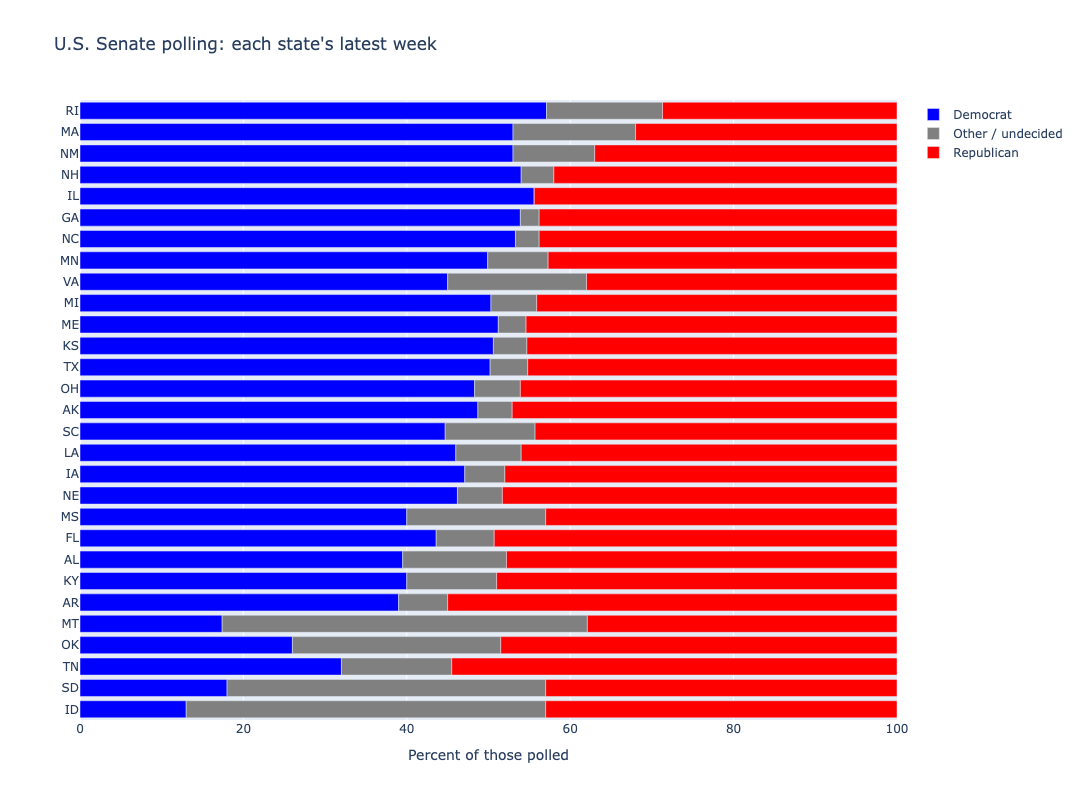

In [5]:
# a dictionary of the names we want in the legend: {old column name: new name}
party_names = {"dem": "Democrat", "other": "Other / undecided", "rep": "Republican"}

# the color of each bar segment, by its new name 
colors = {"Democrat": "blue", "Other / undecided": "grey", "Republican": "red"}

# sort the states from the smallest margin (most Republican) to the largest (most Democratic),
# and rename the columns using the dictionary above
senate_sorted = senate.sort_values("margin").rename(columns=party_names)

fig = px.bar(
    senate_sorted,
    x=["Democrat", "Other / undecided", "Republican"],   # a list of columns: each one becomes a segment, stacked left to right
    y="state",                                           # one bar for each state
    orientation="h",                                     # "h" for horizontal bars
    color_discrete_map=colors,                           # which color goes with which segment
    labels={"value": "Percent", "state": "State"},       # px calls the length of each segment "value" in the hover box
    hover_data={"polls": True, "latest": True},          # also show the number of polls and the latest poll date
    height=800,                                          # tall enough for 29 bars
    title="U.S. Senate polling: each state's latest week",
)

fig.update_layout(
    legend_title_text="",                  # remove the legend's default title
    xaxis_title="Percent of those polled",
    xaxis_range=[0, 100],                  # always show the full 0 to 100 percent
    yaxis_title="",
    yaxis={"dtick": 1},                    # label every bar (otherwise Plotly may label every other one)
)

fig.show()

Hover over a bar to see its numbers. (`dtick=1` makes sure that every state gets a label.)

### House: the closest races

There are 114 polled districts, which is too many for one readable chart. Let's keep the 25 **closest** races. We want the districts with the smallest margin, whichever party is ahead. `abs()` gives a number's size without its sign, and `nsmallest()` picks the smallest rows.

In [6]:
# .abs() drops the minus sign, so a Republican lead of 3 and a Democratic lead of 3 both become 3
house["size_of_lead"] = house["margin"].abs()

# .nsmallest(25, column) keeps the 25 rows with the smallest values in that column.
# Then we sort those 25 by the (signed) margin, to get the same "ladder" as the Senate chart
closest = house.nsmallest(25, "size_of_lead").sort_values("margin")

closest[["id", "dem", "rep", "margin", "polls"]].head()

,id,dem,rep,margin,polls
106,VA-5,46.0,47.7,-1.7,2
16,FL-7,44.5,46.0,-1.5,1
93,TX-9,47.0,48.0,-1.0,1
26,FL-27,46.0,47.0,-1.0,1
13,CO-8,46.4,47.5,-1.0,1


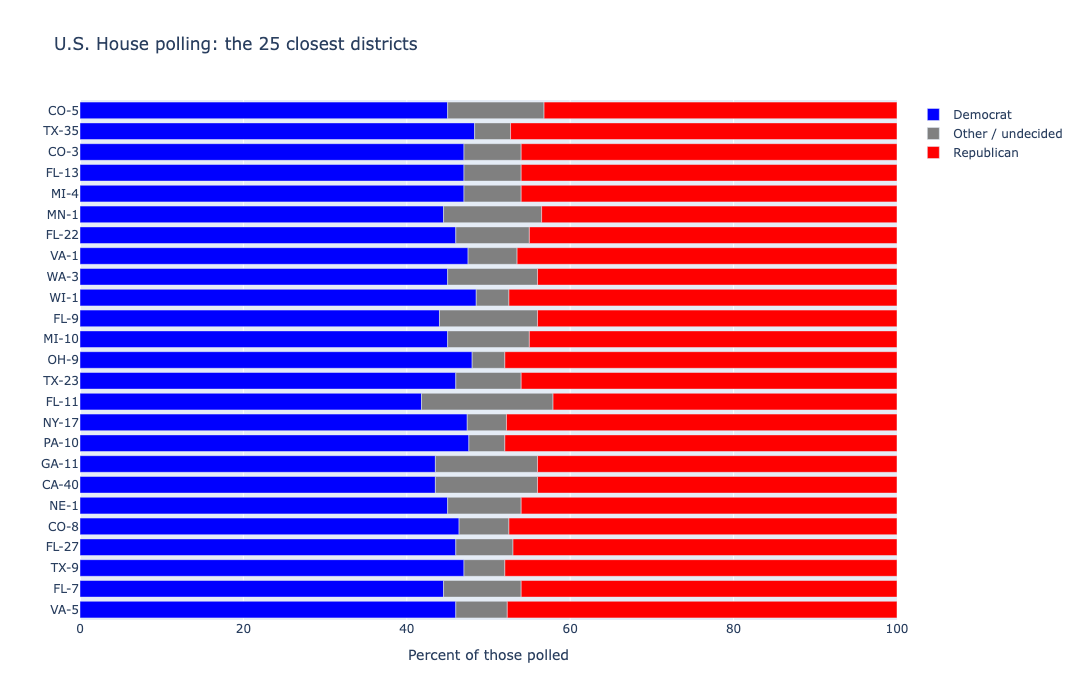

In [7]:
# the same chart as before, using the House table. We reuse party_names and colors from the cell above.
# y="id" gives one bar for each district, labeled like "NY-17"
fig = px.bar(
    closest.rename(columns=party_names),
    x=["Democrat", "Other / undecided", "Republican"],
    y="id",
    orientation="h",
    color_discrete_map=colors,
    labels={"value": "Percent", "id": "District"},
    hover_data={"polls": True, "latest": True},
    height=700,
    title="U.S. House polling: the 25 closest districts",
)

fig.update_layout(
    legend_title_text="",
    xaxis_title="Percent of those polled",
    xaxis_range=[0, 100],
    yaxis_title="",
    yaxis={"dtick": 1},
)

fig.show()

**Things to try**

* Change `25` to `10` or `40`, or change `nsmallest` to `nlargest` to see the *safest* races.
* Make the same chart for just one state's districts: `house[house["state"] == "TX"]`.
* Try `barmode="group"` in `px.bar()` to put the bars side by side instead of stacked.


### 1. A map of Senate races

For info on generating maps with plotly, see: https://plotly.com/python/choropleth-maps/

Senate races are statewide, so we color whole states. Plotly already knows the shapes of U.S. states, so we don't need a shapes file: we give it two-letter state codes and set `locationmode="USA-states"`. The color scale is the same one.

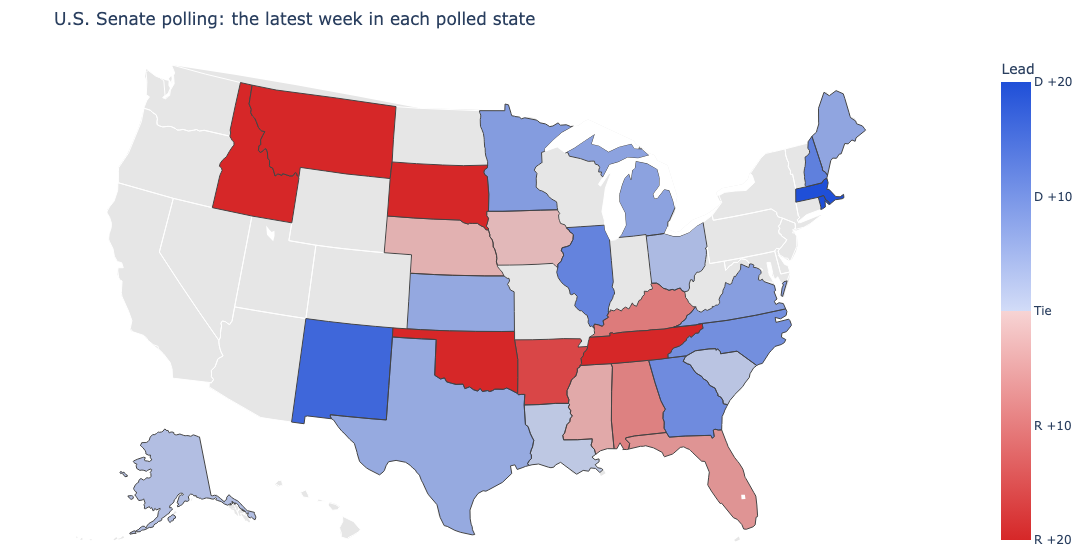

In [14]:
# the red and blue as "red, green, blue" numbers (0 to 255). We'll add the opacity (alpha) in a moment.
red = "214, 39, 40"
blue = "31, 79, 216"

# the color scale: a list of [position, color] pairs, where 0 is the lowest margin (-20) and 1 is the highest (+20).
# Plotly blends smoothly between the positions. The f"..." strings drop the red and blue values into the rgba(...) text.
color_scale = [
    [0.0, f"rgba({red}, 1)"],      # Republican lead of 20+ points: solid red (alpha 1 means fully opaque)
    [0.5, f"rgba({red}, 0.2)"],    # tied: faint (alpha 0.2 means mostly see-through)
    [0.5, f"rgba({blue}, 0.2)"],   # ...and the same position again, so that the color switches from red to blue at a tie
    [1.0, f"rgba({blue}, 1)"],     # Democratic lead of 20+ points: solid blue
]

# the legend (called the "colorbar"): which margins get a label, and what text to write there
colorbar = {
    "title": "Lead",
    "tickvals": [-20, -10, 0, 10, 20],
    "ticktext": ["R +20", "R +10", "Tie", "D +10", "D +20"],
}

# friendlier names for the columns, which Plotly shows when you hover over a shape
labels = {"dem": "Democrat %", "rep": "Republican %", "margin": "Margin", "polls": "Polls", "latest": "Latest poll"}


# px.choropleth() (without "_map") has the U.S. states built in, so there's no geojson argument
fig = px.choropleth(
    senate,
    locations="state",                    # the column with two-letter state codes, like "TX"...
    locationmode="USA-states",            # ...which Plotly knows how to find on its own map of the states
    scope="usa",                          # zoom in on the U.S. (otherwise it shows the whole world)
    color="margin",
    color_continuous_scale=color_scale,   # the same scale and range as the House map
    range_color=[-20, 20],
    hover_name="state",
    hover_data={"state": False, "dem": ":.1f", "rep": ":.1f", "margin": ":.1f", "polls": True, "latest": True},
    labels=labels,
    height=550,
    title="U.S. Senate polling: the latest week in each polled state",
)

# "geos" are the settings of this kind of map. Color the states that have no polling a neutral gray,
# so they can't be mistaken for a faint blue
fig.update_geos(landcolor="#e6e6e6")
fig.update_layout(margin={"l": 0, "r": 0, "t": 50, "b": 0}, coloraxis_colorbar=colorbar)

fig.show()

### 2. A map of House districts


Plotly needs a file of district shapes, which are provided as a geojson file. Each shape has an `id` like `NY-17`, which matches the `id` column of our data.

In [15]:
# open the file and load it, just like the JSON files from Part 9
# (encoding="utf-8" makes sure that accented characters are read correctly)
with open("districts_120th.geojson", "r", encoding="utf-8") as file:
    districts = json.load(file)

# a GeoJSON file is a dictionary with a list of "features", and each feature is one shape
print(len(districts["features"]), "districts")

# every feature also has "properties", the facts about the shape. Here, only an id like "AL-3".
# Plotly will match this id to the id in our table.
print(districts["features"][0]["properties"])

435 districts
{'id': 'AL-3'}


`px.choropleth_map()` colors each shape by a number, here the margin. We give it a custom **color scale**, a list of `[position, color]` pairs from 0 to 1. The colors are written as `rgba(red, green, blue, alpha)`, where the **alpha** (from 0 to 1) is how opaque the color is. So the scale runs from solid red, to a faint color in the middle, to solid blue.

`range_color=[-20, 20]` means that a lead of 20 points or more gets the fully solid color.

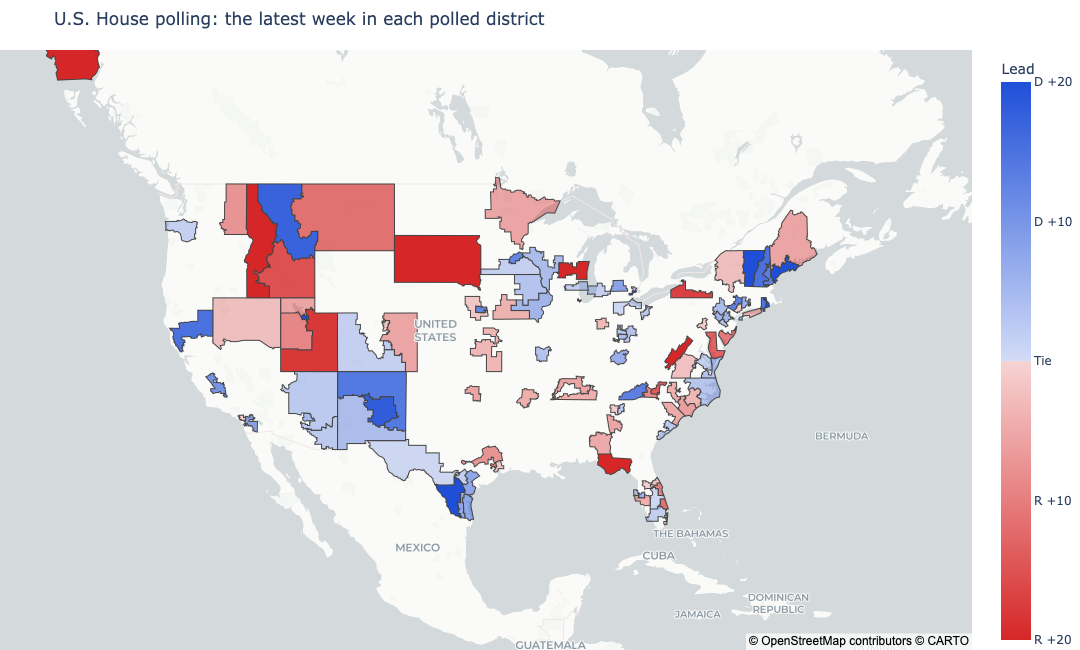

In [16]:

# px.choropleth_map() makes a map where each shape is colored by a number in our table
fig = px.choropleth_map(
    house,                                # the table of data
    geojson=districts,                    # the shapes
    locations="id",                       # the column in our table...
    featureidkey="properties.id",         # ...that matches this property of each shape
    color="margin",                       # the column that decides each shape's color
    color_continuous_scale=color_scale,
    range_color=[-20, 20],                # margins of 20 or more (in either direction) get the strongest color
    hover_name="id",                      # the bold title of the hover box
    # which columns to list in the hover box, and how to format them (":.1f" is one decimal place, False hides one)
    hover_data={"id": False, "dem": ":.1f", "rep": ":.1f", "margin": ":.1f", "polls": True, "latest": True},
    labels=labels,
    map_style="carto-positron",           # the light gray background map
    center={"lat": 38.5, "lon": -96},     # where the map is centered at first (the middle of the U.S.)
    zoom=3,                               # how far in the map starts: a bigger number is closer
    height=650,                           # the height of the figure, in pixels
    title="U.S. House polling: the latest week in each polled district",
)

# update_layout() adjusts what's around the map: the margins (l, r, t, b: left, right, top, bottom) and the legend
fig.update_layout(margin={"l": 0, "r": 0, "t": 50, "b": 0}, coloraxis_colorbar=colorbar)

# show the figure in the notebook
fig.show()

Gray states have no Senate race (or no polling). Some of the colored states are based on a single, old poll: check `polls` and `days_old` in the table.

**Things to discuss and try**

* What does a map show that a bar chart doesn't, and what does a bar chart show that a map doesn't?
* Opacity only shows the *size* of the lead. A state with one poll looks the same as one with 50, even though the first is much less certain. How could the map show that?
* Which map is easier to read, the House districts or the Senate states? Large, sparsely populated areas dominate the picture. What could you do about that?
* Look at `senate.sort_values("days_old", ascending=False).head()`. Should these old polls be on the map?
* Go back to `week10_polling_prep.ipynb`, change `DAYS` to 14, rerun it, and then rerun the maps.
* Try `px.choropleth_map()` for the Senate. You'd need a file of state shapes.

## Housing construction in New York City, in 3D

here's how we can create a 3D map using NYC Open Data on new housing units.

1. Load the housing data, one row per community district
2. Add up the net housing units completed in each district
3. Attach the numbers to each district's shape, and **extrude** the shapes: raise each by its number of units.
4. Show change over time with a cluster of bars in each district.

### 1. Load the data

The numbers in this file have thousands separators (like `1,604`), which pandas would read as text. The `thousands=","` option makes `read_csv()` treat them as numbers.

In [35]:
# thousands="," tells pandas that a comma inside a number, like 1,604, is a separator and not part of the text
nyc = pd.read_csv("Housing_Database_by_Community_District_20261102.csv", thousands=",")

# .shape is (number of rows, number of columns)
print(nyc.shape)

# the table has many columns, so we pick out a few to look at: the district code, some years, and the 2020 census count
nyc[["commntydst", "comp2011", "comp2012", "comp2025", "comp2026", "cenunits20"]].head()

(71, 28)


,commntydst,comp2011,comp2012,comp2025,comp2026,cenunits20
0,101,1604,503,1513,1684,41977
1,102,-30,-94,46,292,58418
2,103,122,70,349,203,82589
3,104,1987,298,451,282,84357
4,105,320,-125,222,292,42323


The columns `comp2011` through `comp2026` are the **net housing units completed** in each year ("net" because demolished units are subtracted). `cenunits20` is the number of housing units counted in the 2020 Census. (2026 is a partial year.)

`commntydst` is a code: the first digit is the borough, and the last two digits are the district number. Numbers above 18 are parks and airports, not districts.

In [36]:
# the first digit of the code is the borough
boroughs = {1: "Manhattan", 2: "Bronx", 3: "Brooklyn", 4: "Queens", 5: "Staten Island"}

# for a code like 305: 305 // 100 is 3 (Brooklyn), and 305 % 100 is 5 (district 5).
# .map() swaps each number for its name in the dictionary
nyc["borough"] = (nyc["commntydst"] // 100).map(boroughs)       # // is whole-number division
nyc["number"] = nyc["commntydst"] % 100                         # % is the remainder

# a readable name like "Brooklyn CD 5" (CD means community district).
# .astype(str) turns the numbers into text, so that they can be joined with + to other text
nyc["label"] = nyc["borough"] + " CD " + nyc["number"].astype(str)

# True for the real districts (numbers 1 to 18), and False for the parks and airports
nyc["is_district"] = nyc["number"] <= 18

nyc[["commntydst", "label", "is_district"]].head()

,commntydst,label,is_district
0,101,Manhattan CD 1,True
1,102,Manhattan CD 2,True
2,103,Manhattan CD 3,True
3,104,Manhattan CD 4,True
4,105,Manhattan CD 5,True


### 2. Totals and growth

In [37]:
# a list of column names: ["comp2011", "comp2012", ..., "comp2026"]. range(2011, 2027) stops before 2027
year_columns = [f"comp{year}" for year in range(2011, 2027)]

# .sum(axis=1) adds up each row across those columns (axis=0 would add down each column)
nyc["completed"] = nyc[year_columns].sum(axis=1)

# the growth as a percentage of the number of homes in the 2020 census
nyc["growth_pct"] = nyc["completed"] / nyc["cenunits20"] * 100

nyc[nyc["is_district"]].sort_values("completed", ascending=False)[["label", "completed", "growth_pct"]].head(5).round(1)

,label,completed,growth_pct
28,Brooklyn CD 1,30204,33.6
29,Brooklyn CD 2,27237,40.7
49,Queens CD 2,25539,42.0
3,Manhattan CD 4,19342,22.9
48,Queens CD 1,16409,18.1


### 3. Attach the numbers to the shapes

The shapes file has one **feature** for each community district, with a `commntydst` code that matches our table. Each feature has a `properties` dictionary, and pydeck can read any of its values. So we loop over the features and add what we want to show.

First, turn the table into a dictionary we can look things up in: `{101: {...the row...}, 102: {...}}`.

In [38]:
# load the shapes, the same way as for the House districts
with open("nyc_districts.geojson", "r", encoding="utf-8") as file:
    shapes = json.load(file)

# .set_index() makes the district code the row label, and .to_dict("index") turns the table into a dictionary
# of dictionaries: {101: {"label": "Manhattan CD 1", "completed": ..., ...}, 102: {...}, ...}
rows = nyc.set_index("commntydst").to_dict("index")

print(len(shapes["features"]), "shapes")

# each shape's properties have its district code, and the longitude and latitude of its center
print(shapes["features"][0]["properties"])

# look up one district in our dictionary: first by its code, then by the column we want
print(rows[101]["label"], rows[101]["completed"])

71 shapes
{'commntydst': 101, 'lon': -74.012, 'lat': 40.70738}
Manhattan CD 1 13326


Now the loop. Each district gets:

* a **height**: its completed units (negative totals become 0, since a bar can't point down),
* a **color**: lighter yellow for little growth, darker red for a lot, and gray for parks and airports. Colors are `[red, green, blue, alpha]` lists, with numbers from 0 to 255.

In [39]:
# the growth that counts as "a lot": the 95th percentile (only 5% of districts grew more than this).
# Using it as the top of the scale keeps one extreme district from making every other district look pale
top_growth = nyc.loc[nyc["is_district"], "growth_pct"].quantile(.95)


def growth_color(growth_pct):
    """Turn a growth percentage into a [red, green, blue, alpha] color, from pale yellow to dark red."""
    # share is how far along the scale we are: 0 means no growth, 1 means top_growth or more.
    # max(..., 0) stops it going below 0, and min(..., 1) stops it going above 1
    share = min(max(growth_pct / top_growth, 0), 1)

    # slide each color channel from pale yellow (255, 237, 160) toward dark red (189, 0, 38)
    return [int(255 - 66 * share), int(237 - 237 * share), int(160 - 122 * share), 230]


# go through every shape. Each one is a dictionary, so changing its "properties" changes the shapes data itself
for feature in shapes["features"]:
    # find this district's row in our dictionary, using the code stored in the shape
    row = rows[feature["properties"]["commntydst"]]

    if row["is_district"]:
        feature["properties"]["height"] = max(row["completed"], 0)       # a bar can't point down, so negatives become 0
        feature["properties"]["color"] = growth_color(row["growth_pct"])
    else:
        feature["properties"]["height"] = 0                              # parks and airports stay flat...
        feature["properties"]["color"] = [210, 210, 210, 200]            # ...and gray

    # the facts that we want to show in the hover box
    feature["properties"]["label"] = row["label"]
    feature["properties"]["completed"] = int(row["completed"])
    feature["properties"]["growth_pct"] = round(row["growth_pct"], 1)

# check the first shape: it now has all of the new properties

shapes["features"][0]["properties"]

{'commntydst': 101,
 'lon': -74.012,
 'lat': 40.70738,
 'height': 13326,
 'color': [192, 13, 44, 230],
 'label': 'Manhattan CD 1',
 'completed': 13326,
 'growth_pct': 31.7}

### 4. The extruded map

A pydeck map is built from **layers**. A `GeoJsonLayer` with `extruded=True` raises each shape by the `height` property. `elevation_scale` converts our unit counts into meters on the map, so tune it to taste. The `ViewState` sets the camera: the center point, zoom, `pitch` (tilt), and `bearing` (rotation).

In [42]:
# a layer: one kind of drawing on the map. "GeoJsonLayer" draws the shapes in a GeoJSON dictionary
extruded = pdk.Layer(
    "GeoJsonLayer",
    data=shapes,                             # our shapes, now with height and color properties
    extruded=True,                           # raise the shapes up into 3D
    get_elevation="properties.height",       # how high to raise each one: read from its "height" property
    elevation_scale=0.1,                     # meters of height per housing unit: a bigger number makes taller shapes
    get_fill_color="properties.color",       # each shape's color: read from its "color" property
    get_line_color=[255, 255, 255],          # white outlines
    pickable=True,                           # allow hovering, to see the tooltip
    auto_highlight=True,                     # light up the shape under the mouse
)

# the camera. pitch tilts the view (0 is straight down), and bearing rotates it (in degrees)
view = pdk.ViewState(latitude=40.71, longitude=-73.95, zoom=9.8, pitch=55, bearing=20)

# a Deck puts the layers, the camera, and the background map together
deck = pdk.Deck(
    layers=[extruded],
    initial_view_state=view,
    map_style="light",                       # a light gray background map
    # the hover box: {name} is replaced with that property of the shape under the mouse
    tooltip={"html": "<b>{label}</b><br/>Net units completed 2011-2026: {completed}<br/>Growth vs. 2020 census: {growth_pct}%"},
)

# save the map as a web page, then display that page inside the notebook
deck.to_html("nyc_housing_extruded.html", open_browser=False)
IFrame("nyc_housing_extruded.html", width="100%", height=650)

Drag to pan, scroll to zoom, and **hold Ctrl (or right-click) and drag to tilt and rotate**. Hover over a district for its numbers.

We save the map as an HTML file and show it in an `IFrame`, which works in almost every Jupyter setup. (The map needs an internet connection to load its background.)

Tall bars hide what's behind them, and perspective makes heights hard to compare. What would you change?

### 5. Change over time: clusters of bars

To show *change*, give each district three bars, one for each period, side by side. A `ColumnLayer` draws a column at each longitude/latitude point, so we make a list with one dictionary per bar. Each shape has the longitude and latitude of its center in its properties, and we shift each period's bar a little to the east or west.

In [43]:
# the three periods, and the years in each
periods = {
    "2011-2015": [2011, 2012, 2013, 2014, 2015],
    "2016-2020": [2016, 2017, 2018, 2019, 2020],
    "2021-2026": [2021, 2022, 2023, 2024, 2025, 2026],       # six years, because 2026 is a partial year
}

# how far to move each period's bar from the center of the district, in degrees of longitude:
# the earliest period goes west (negative), the latest goes east (positive)
shift = {"2011-2015": -0.007, "2016-2020": 0, "2021-2026": 0.007}

# each period's color: light blue to dark blue, as [red, green, blue, alpha]
palette = {"2011-2015": [158, 202, 225, 240], "2016-2020": [66, 146, 198, 240], "2021-2026": [8, 69, 148, 240]}

# we'll build a list with one dictionary for each bar (each district has three)
bars = []

for feature in shapes["features"]:
    properties = feature["properties"]
    row = rows[properties["commntydst"]]

    # skip the parks and airports: continue jumps straight to the next shape
    if not row["is_district"]:
        continue

    # a loop inside the loop: this district gets one bar for each period
    for period, period_years in periods.items():
        # add up the completed units over this period's years
        units = sum(row[f"comp{year}"] for year in period_years)

        bars.append({
            "label": row["label"],
            "period": period,
            "units": max(int(units), 0),                     # a bar can't point down, so negatives become 0
            "lon": properties["lon"] + shift[period],        # the district's center, nudged east or west
            "lat": properties["lat"],
            "color": palette[period],
        })

# a list of dictionaries with the same keys becomes a table
bars = pd.DataFrame(bars)

# check: 59 districts times 3 periods is 177 bars. Then, the smallest, average, and largest bar in each period
print(len(bars), "bars")
bars.groupby("period")["units"].agg(["min", "mean", "max"]).round(0)

177 bars


,min,mean,max
period,,,
2011-2015,0,1207.0,7480
2016-2020,128,2161.0,10443
2021-2026,193,3147.0,12562


In [44]:
# the first layer is the flat map of the districts, in light gray, as a background for the bars
flat_map = pdk.Layer(
    "GeoJsonLayer",
    data=shapes,
    get_fill_color=[225, 225, 225, 200],
    get_line_color=[255, 255, 255],
    line_width_min_pixels=1,                 # keep the outlines visible, even when zoomed out
)

# the second layer draws one column for each row of our bars table
columns = pdk.Layer(
    "ColumnLayer",
    data=bars,
    get_position=["lon", "lat"],             # which columns hold each bar's longitude and latitude
    get_elevation="units",                   # the column that sets each bar's height
    elevation_scale=0.2,                     # meters of height per housing unit
    radius=230,                              # column radius in meters
    get_fill_color="color",                  # the column that holds each bar's color
    extruded=True,                           # draw the columns as 3D shapes
    pickable=True,
    auto_highlight=True,
)

# layers are drawn in order, so the flat map goes first and the columns stand on top of it
deck_columns = pdk.Deck(
    layers=[flat_map, columns],
    initial_view_state=pdk.ViewState(latitude=40.71, longitude=-73.95, zoom=10, pitch=55, bearing=20),
    map_style="light",
    tooltip={"html": "<b>{label}</b><br/>{period}: {units} net units completed"},
)

deck_columns.to_html("nyc_housing_columns.html", open_browser=False)
IFrame("nyc_housing_columns.html", width="100%", height=650)

In [46]:
# pydeck doesn't make a legend, so we write one in HTML: a small colored box (&nbsp; is a space) beside each period's name
HTML(
    "<b>Net housing units completed:</b> "
    "<span style='background:rgb(158,202,225)'>&nbsp;&nbsp;&nbsp;</span> 2011-2015 &nbsp; "
    "<span style='background:rgb(66,146,198)'>&nbsp;&nbsp;&nbsp;</span> 2016-2020 &nbsp; "
    "<span style='background:rgb(8,69,148)'>&nbsp;&nbsp;&nbsp;</span> 2021-2026 (six years)"
)

**Things to try**

* Change `elevation_scale`, `radius`, or `pitch`, and rerun. How does the story change?
* Which districts grew the most in the last period? Try `bars[bars["period"] == "2021-2026"].sort_values("units", ascending=False).head()`.
* The data also has the **pipeline**: units that have been filed, approved, or permitted but not completed. Map those instead.

# Word clouds

A **word cloud** draws words at sizes that show how often they appear. The `wordcloud` library turns a text, or a table of word counts, into an image. We'll use a whole book: *How the Other Half Lives: Studies Among the Tenements of New York* (1890), by Jacob A. Riis, a journalist and photographer who documented life in the city's tenements. The text comes from [Project Gutenberg](https://www.gutenberg.org/ebooks/45502).

### 1. Get the text

In [47]:
# read the whole book into one string, the same way we read other text files
# (encoding="utf-8" makes sure that special characters are read correctly)
with open("riis.txt", "r", encoding="utf-8") as file:
    book = file.read()

# Project Gutenberg adds a license and some information before and after the book. Each is separated from the
# book by a line starting with "*** START OF" or "*** END OF". .index() gives the position of that text in the string
start = book.index("*** START OF")
end = book.index("*** END OF")

# move the start to the end of the "START" line: the next newline ("\n") after it
start = book.index("\n", start)

# slice the string to keep only what is between the two markers
text = book[start:end]

print(len(book), "characters in the file,", len(text), "in the actual text")

491930 characters in the file, 472261 in the actual text


`WordCloud` wants **one long string**, and `text` is already one. Let's check the beginning and the end. We kept the whole book, and the end has a few notes from the people who prepared this edition, which are small enough to leave in.

In [53]:
# text[:300] is the first 300 characters, and text[-300:] is the last 300
print(text[:300])
print("...")
print(text[-300:])

# .split() cuts a string into words wherever there is a space or a line break, so len() of the result is a word count
print(len(text.split()), "words")



                        HOW THE OTHER HALF LIVES

  [Illustration: GOTHAM COURT.]




                        HOW THE OTHER HALF LIVES

                      _STUDIES AMONG THE TENEMENTS
                              OF NEW YORK_


                                   BY
                            
...
 disenfecting                  _sic_

p.  77  loadstone                     _sic_

p.  82  caravanseries                 _sic_

p. 107  tha[t/n]                      Corrected.

p. 256  tantilizes                    _sic_





End of Project Gutenberg's How the Other Half Lives, by Jacob A. Riis




81813 words


### 2. A first word cloud

`generate()` counts the words and lays them out. `plt.imshow()` displays the image, and `plt.axis("off")` hides the plot's axes. `random_state` makes the layout the same every time.

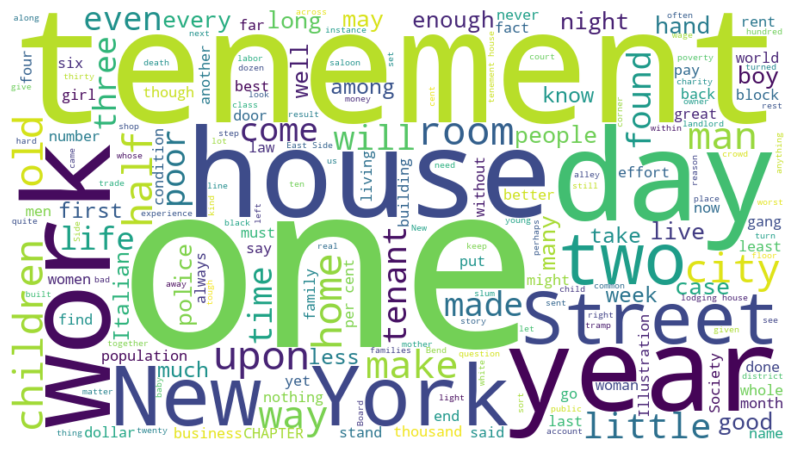

In [55]:
# make the cloud: the size of the image in pixels, a white background, and a fixed random_state
# (the layout uses random choices, and a fixed number makes them the same every time)
cloud = WordCloud(width=900, height=500, background_color="white", random_state=1).generate(text)

plt.figure(figsize=(10, 6))                  # the size of the plot, in inches
plt.imshow(cloud, interpolation="bilinear")  # draw the cloud's image (bilinear smooths it)
plt.axis("off")                              # hide the plot's axes
plt.show()

`WordCloud` already leaves out common English words such as "of" and "the" (its **stop words**), but the result is still full of ordinary words like "one", "upon", and "will". Notice, too, that it counts some **pairs** of words together, like "New York".

### 3. Choose the words to leave out

`STOPWORDS` is a set of words. We can add our own with `|` (the union of two sets) and pass the result to `WordCloud`.

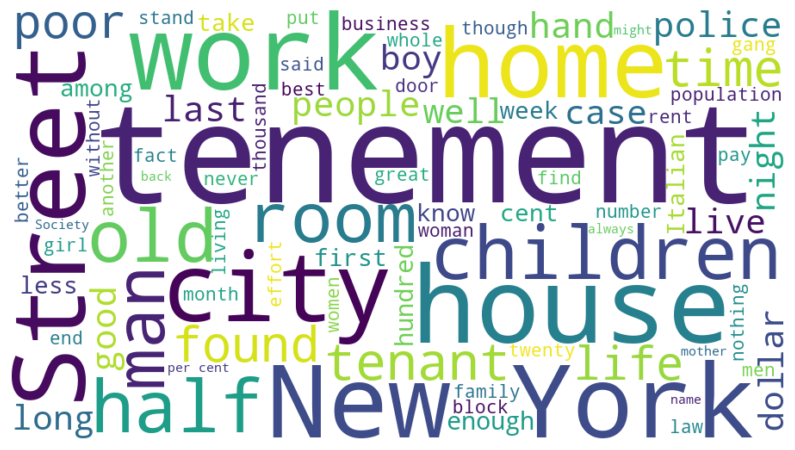

In [56]:
# STOPWORDS is a set, and | joins two sets together: the built-in stop words, plus a set of our own.
# Look at the first cloud, and add the words that are common but don't tell us much about this book
my_stopwords = STOPWORDS | {
    "one", "two", "three", "four", "five", "six", "upon", "will", "may", "even", "every", "many", "made", "make",
    "much", "must", "way", "now", "yet", "still", "little", "see", "seen", "come", "came", "day", "year", "years",
    "chapter", "illustration",           # headings and captions in the book, not part of its text
}

cloud = WordCloud(
    width=900,
    height=500,
    background_color="white",
    stopwords=my_stopwords,      # the words to leave out
    colormap="viridis",          # the color palette: try "plasma", "Set2", "Blues"
    max_words=80,                # only draw the 80 most common words
    random_state=1,
).generate(text)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

### 4. A cloud from counts

We don't have to start from text. If we already have **counts**, like the output of `value_counts()`, `generate_from_frequencies()` draws a cloud from a dictionary of `{word: count}`. That gives us full control over what gets counted. Here, we'll use a regular expression from Part 9 to pull out the words, count them with pandas, and drop the stop words ourselves.

[('street', 268), ('tenement', 223), ('new', 199), ('tenements', 193), ('house', 156)]


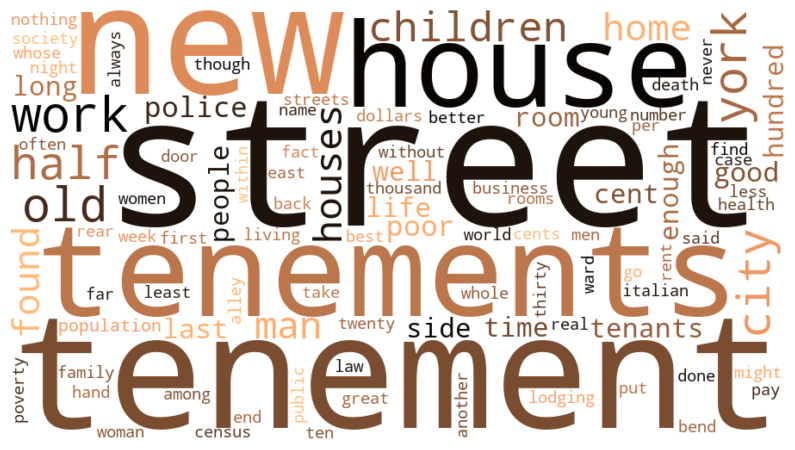

In [57]:
# re.findall() returns every match of a pattern. [a-z']+ means "one or more lowercase letters or apostrophes",
# so each match is a word. We lowercase the text first, so that "The" and "the" are counted together
words = re.findall(r"[a-z']+", text.lower())

# a list of words becomes a pandas Series, and .value_counts() counts each one, with the most common first
counts = pd.Series(words).value_counts()

# .isin() is True for the words that are in our set of stop words. The ~ flips it, so we keep the other words
counts = counts[~counts.index.isin(my_stopwords)]

# the 100 most common words, as a dictionary like {"tenement": 317, "street": 157, ...}
word_counts = counts.head(100).to_dict()

# a dictionary's .items() are its (key, value) pairs. We make a list of them and look at the first five
print(list(word_counts.items())[:5])

# this time we make the WordCloud first, and then give it the counts with a second call
cloud = WordCloud(width=900, height=500, background_color="white", colormap="copper", random_state=1)
cloud = cloud.generate_from_frequencies(word_counts)

plt.figure(figsize=(10, 6))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

Save a cloud as an image file with `to_file()`:

In [52]:
# save the most recent cloud as a PNG image, in this folder
cloud.to_file("riis_cloud.png")

### Things to try

* Change `max_words`, `colormap`, or the size of the image, and rerun.
* In the first clouds, `WordCloud` counted pairs like "New York". Add `collocations=False` to `WordCloud(...)` to count single words only. What changes?
* Make a cloud from **a different text**: another book from [Project Gutenberg](https://www.gutenberg.org/) (choose "Plain Text UTF-8")